In [12]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [13]:
DATA_DIR = Path(r"C:\Users\rivam\Downloads\archive")

print(DATA_DIR)
print(DATA_DIR.exists())

C:\Users\rivam\Downloads\archive
True


In [14]:
image_extensions = {".jpg", ".jpeg", ".png"}

image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in image_extensions
]

print("Number of images:", len(image_paths))
print("\nExample:")
print(image_paths[0])


Number of images: 7200

Example:
C:\Users\rivam\Downloads\archive\Training\glioma\Tr-gl_1.jpg


In [15]:
from pathlib import Path
import random
from collections import Counter

DATA_DIR = Path(r"C:\Users\rivam\Downloads\archive")

# Find image files
image_extensions = {".jpg", ".jpeg", ".png"}

all_image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in image_extensions
]

# Group images by their parent folder
images_by_class = {}

for path in all_image_paths:
    class_name = path.parent.name
    images_by_class.setdefault(class_name, []).append(path)

# Inspect the available classes
for class_name, paths in sorted(images_by_class.items()):
    print(f"{class_name}: {len(paths)} images")

glioma: 1800 images
meningioma: 1800 images
notumor: 1800 images
pituitary: 1800 images


In [16]:
random.seed(42)

MAX_PER_CLASS = 250

image_paths = []

for class_name, paths in sorted(images_by_class.items()):
    n = min(MAX_PER_CLASS, len(paths))
    image_paths.extend(random.sample(paths, n))

# Shuffle the combined selection
random.shuffle(image_paths)

print("\nTotal selected:", len(image_paths))

print("\nSelected images by category:")
print(Counter(p.parent.name for p in image_paths))


Total selected: 1000

Selected images by category:
Counter({'notumor': 250, 'pituitary': 250, 'glioma': 250, 'meningioma': 250})


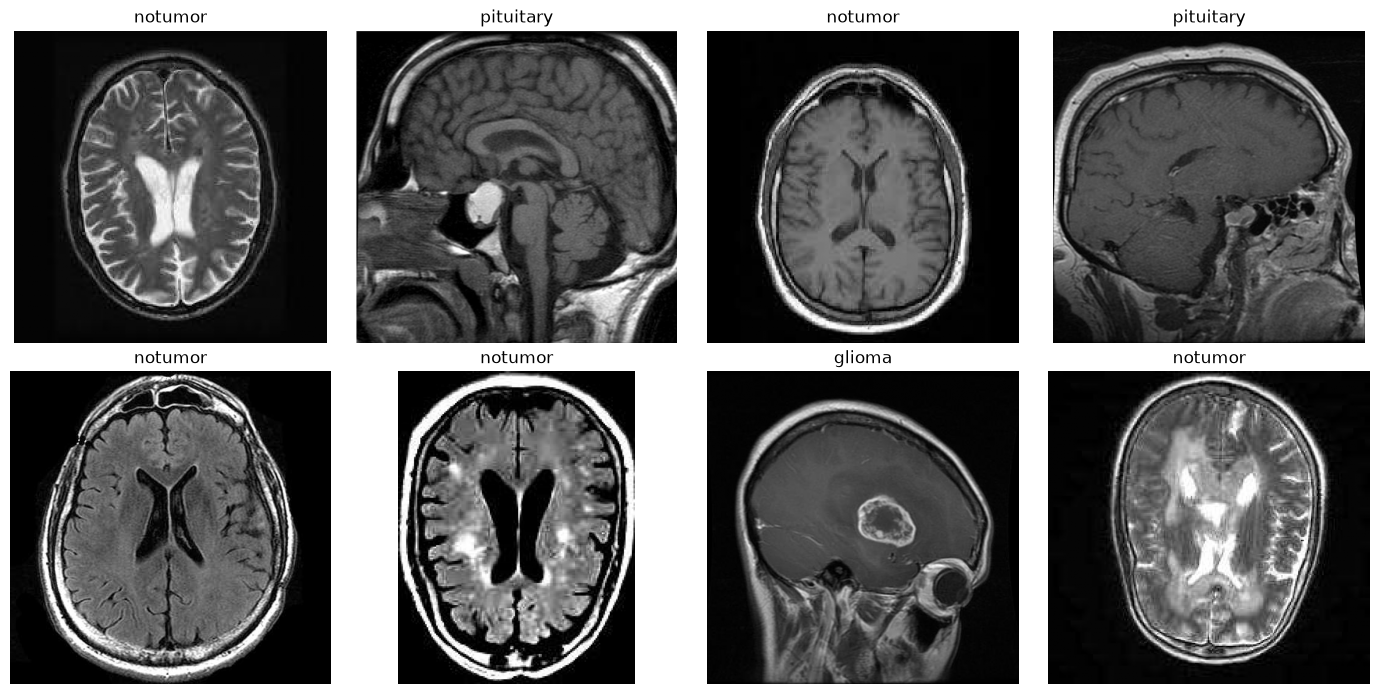

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, path in zip(axes.ravel(), image_paths[:8]):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    
    ax.imshow(img, cmap="gray")
    ax.set_title(path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
def add_gaussian_noise(image, sigma):
    """
    Add Gaussian noise to an MRI image.
    """
    noise = np.random.normal(0, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_blur(image, kernel_size):
    """
    Add Gaussian blur to simulate loss of sharpness.
    """
    return cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        0
    )


def degrade_image(image, quality):
    """
    Generate different quality levels.

    0 = Good
    1 = Moderate
    2 = Poor
    """
    
    if quality == 0:
        return image
    
    elif quality == 1:
        # Moderate degradation
        image = add_gaussian_noise(image, sigma=15)
        image = add_blur(image, kernel_size=3)
        return image
    
    elif quality == 2:
        # Severe degradation
        image = add_gaussian_noise(image, sigma=35)
        image = add_blur(image, kernel_size=7)
        return image

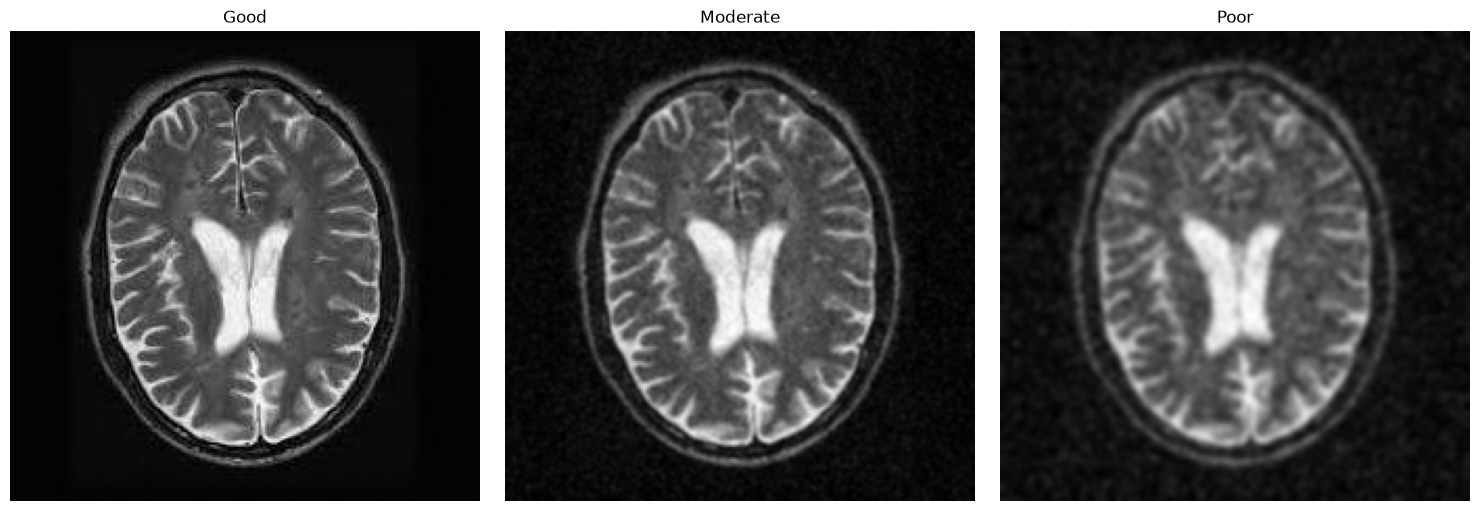

In [19]:
sample = cv2.imread(
    str(image_paths[0]),
    cv2.IMREAD_GRAYSCALE
)

good = degrade_image(sample, 0)
moderate = degrade_image(sample, 1)
poor = degrade_image(sample, 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(good, cmap="gray")
axes[0].set_title("Good")

axes[1].imshow(moderate, cmap="gray")
axes[1].set_title("Moderate")

axes[2].imshow(poor, cmap="gray")
axes[2].set_title("Poor")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
import cv2
import numpy as np
from skimage.measure import shannon_entropy


def extract_features(image):
    """
    Extract quantitative image-quality features from a grayscale MRI.

    Parameters
    ----------
    image : numpy.ndarray
        Grayscale MRI image.

    Returns
    -------
    dict
        Dictionary containing image-quality features.
    """

    # Convert to uint8 grayscale if necessary
    image = np.asarray(image)

    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    image = np.clip(image, 0, 255).astype(np.uint8)

    # Normalize intensities to [0, 1]
    img = image.astype(np.float32) / 255.0

    # 1. Intensity statistics
    mean_intensity = float(np.mean(img))
    std_intensity = float(np.std(img))
    median_intensity = float(np.median(img))

    # 2. Intensity contrast
    contrast = float(np.percentile(img, 95) - np.percentile(img, 5))

    # 3. Entropy
    entropy = float(shannon_entropy(image))

    # 4. Sharpness using variance of the Laplacian
    sharpness = float(cv2.Laplacian(img, cv2.CV_32F).var())

    # 5. Edge density
    edges = cv2.Canny(image, 100, 200)
    edge_density = float(np.mean(edges > 0))

    # 6. Gradient magnitude
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    gradient_magnitude = np.sqrt(gx**2 + gy**2)
    mean_gradient = float(np.mean(gradient_magnitude))

    # 7. Intensity percentiles
    p10 = float(np.percentile(img, 10))
    p25 = float(np.percentile(img, 25))
    p75 = float(np.percentile(img, 75))
    p90 = float(np.percentile(img, 90))

    return {
        "mean_intensity": mean_intensity,
        "std_intensity": std_intensity,
        "median_intensity": median_intensity,
        "contrast": contrast,
        "entropy": entropy,
        "sharpness": sharpness,
        "edge_density": edge_density,
        "mean_gradient": mean_gradient,
        "p10": p10,
        "p25": p25,
        "p75": p75,
        "p90": p90
    }

In [21]:
sample_path = image_paths[0]

sample_image = cv2.imread(
    str(sample_path),
    cv2.IMREAD_GRAYSCALE
)

features = extract_features(sample_image)

print("Image:", sample_path.name)
print("\nExtracted features:")

for feature, value in features.items():
    print(f"{feature}: {value:.6f}")

Image: Tr-no_530.jpg

Extracted features:
mean_intensity: 0.188471
std_intensity: 0.224890
median_intensity: 0.043137
contrast: 0.674510
entropy: 5.905531
sharpness: 0.015735
edge_density: 0.098193
mean_gradient: 0.267151
p10: 0.015686
p25: 0.015686
p75: 0.309804
p90: 0.478431


In [22]:
import pandas as pd
from tqdm.auto import tqdm

# Quality labels
QUALITY_LABELS = {
    0: "Good",
    1: "Moderate",
    2: "Poor"
}

records = []

for path in tqdm(image_paths, desc="Processing MRI images"):

    original = cv2.imread(
        str(path),
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        continue

    # Process all three quality levels
    for quality in [0, 1, 2]:

        degraded = degrade_image(original, quality)

        features = extract_features(degraded)

        # Metadata
        features["original_id"] = str(path)
        features["source_class"] = path.parent.name
        features["quality_label"] = quality
        features["quality_name"] = QUALITY_LABELS[quality]

        records.append(features)

# Create a DataFrame
df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nQuality distribution:")
print(df["quality_name"].value_counts())

df.head()

Processing MRI images:   0%|          | 0/1000 [00:00<?, ?it/s]

Dataset shape: (3000, 16)

Quality distribution:
quality_name
Good        1000
Moderate    1000
Poor        1000
Name: count, dtype: int64


,mean_intensity,std_intensity,median_intensity,contrast,entropy,sharpness,edge_density,mean_gradient,p10,p25,p75,p90,original_id,source_class,quality_label,quality_name
0,0.188471,0.224890,0.043137,0.674510,5.905531,0.015735,0.098193,0.267151,0.015686,0.015686,0.309804,0.478431,C:\Users\rivam\Downloads\archive\Training\notu...,notumor,0,Good
1,0.194184,0.213346,0.070588,0.635294,6.581965,0.003754,0.093017,0.262463,0.023529,0.035294,0.313726,0.470588,C:\Users\rivam\Downloads\archive\Training\notu...,notumor,1,Moderate
2,0.210933,0.192593,0.105882,0.568627,6.655345,0.000688,0.059773,0.195352,0.050980,0.066667,0.321569,0.458824,C:\Users\rivam\Downloads\archive\Training\notu...,notumor,2,Poor
3,0.264845,0.186180,0.254902,0.654902,7.183332,0.007487,0.037413,0.200541,0.023529,0.141176,0.345098,0.450980,C:\Users\rivam\Downloads\archive\Training\pitu...,pituitary,0,Good
4,0.264924,0.179923,0.250980,0.619608,7.243351,0.002094,0.040674,0.217280,0.039216,0.141176,0.345098,0.450980,C:\Users\rivam\Downloads\archive\Training\pitu...,pituitary,1,Moderate


In [23]:
from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_path = OUTPUT_DIR / "mri_quality_features.csv"

df.to_csv(features_path, index=False)

print("Saved to:", features_path.resolve())

Saved to: C:\Users\rivam\Desktop\MRI-Image-Quality-Assessment\results\mri_quality_features.csv


In [24]:
import pandas as pd
from pathlib import Path

features_path = Path("../results/mri_quality_features.csv")

df = pd.read_csv(features_path)

print("Dataset shape:", df.shape)
print("Original MRI images:", df["original_id"].nunique())
print(df["quality_name"].value_counts())

Dataset shape: (3000, 16)
Original MRI images: 1000
quality_name
Good        1000
Moderate    1000
Poor        1000
Name: count, dtype: int64


In [25]:
from sklearn.model_selection import GroupShuffleSplit

feature_columns = [
    "mean_intensity",
    "std_intensity",
    "median_intensity",
    "contrast",
    "entropy",
    "sharpness",
    "edge_density",
    "mean_gradient",
    "p10",
    "p25",
    "p75",
    "p90"
]

X = df[feature_columns]
y = df["quality_label"]
groups = df["original_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_ids = set(groups.iloc[train_idx])
test_ids = set(groups.iloc[test_idx])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training originals:", len(train_ids))
print("Testing originals:", len(test_ids))

assert train_ids.isdisjoint(test_ids)

print("No original-image leakage detected.")

Training samples: 2400
Testing samples: 600
Training originals: 800
Testing originals: 200
No original-image leakage detected.


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
display(results_df)

Training Logistic Regression...
Training Random Forest...


,Model,Accuracy,Weighted F1
0,Logistic Regression,0.946667,0.946787
1,Random Forest,0.986667,0.986631


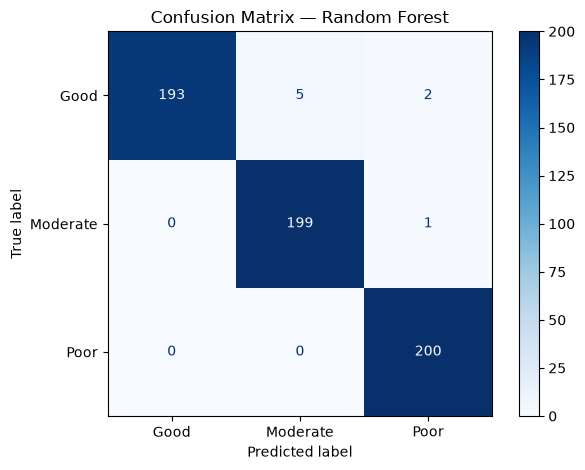

Best model: Random Forest


In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_model_name = results_df.sort_values(
    "Weighted F1", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Good", "Moderate", "Poor"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(
    "../results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Best model:", best_model_name)

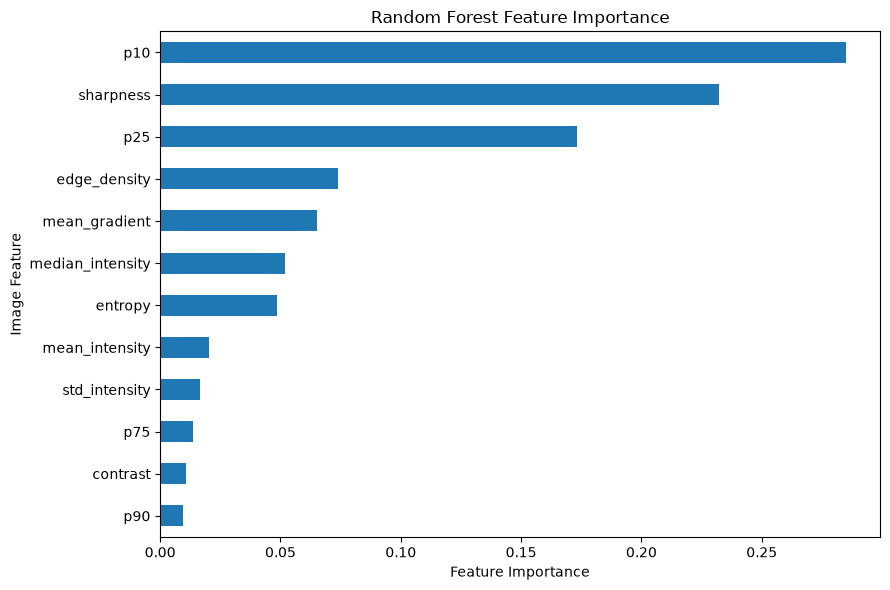

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

rf_model = trained_models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_columns
).sort_values()

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Image Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    "../results/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

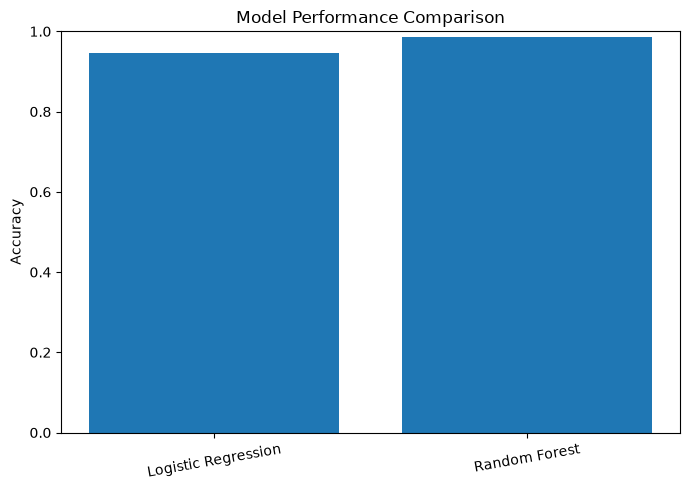

In [29]:
plt.figure(figsize=(7, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Model Performance Comparison")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "../results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()